EDA Report

**Project:** Mining EV Registration Patterns in Washington State  
**Authors:** Afsana Tasnim Juha, Mamata Joshi, Prasanna Thapa





## Data Preparation

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
DATA_PATH = Path("data/raw/ev_sample_50k.csv")
df = pd.read_csv(DATA_PATH)
df["Postal Code"] = (
    df["Postal Code"].astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)
df["Electric Range Usable"] = df["Electric Range"].where(df["Electric Range"] > 0)

df_wa = df.loc[
    (df["State"] == "WA") &
    df["Postal Code"].str.fullmatch(r"\d{5}").fillna(False)
].copy()
df_wa["Is BEV"] = df_wa["Electric Vehicle Type"] == "Battery Electric Vehicle (BEV)"
df_wa["Is PHEV"] = df_wa["Electric Vehicle Type"].str.contains("PHEV")

zip_summary = df_wa.groupby("Postal Code").agg(
    EV_Count=("DOL Vehicle ID", "count"),
    BEV_Count=("Is BEV", "sum"),
    PHEV_Count=("Is PHEV", "sum"),
    Avg_Model_Year=("Model Year", "mean"),
    Avg_Electric_Range=("Electric Range Usable", "mean"),
    Valid_Range_Count=("Electric Range Usable", "count")
).reset_index()
zip_summary["BEV_Percentage"] = (zip_summary["BEV_Count"] / zip_summary["EV_Count"] * 100).round(2)

print("Rows in sample:", len(df), "| WA rows kept:", len(df_wa))
print("ZIP codes:", len(zip_summary))
print(zip_summary["EV_Count"].describe())

Rows in sample: 50000 | WA rows kept: 49873
ZIP codes: 509
count     509.000000
mean       97.982318
std       150.941995
min         1.000000
25%         4.000000
50%        27.000000
75%       136.000000
max      1208.000000
Name: EV_Count, dtype: float64


## ZIP sample sizes and skew

ZIPs with fewer than 5 vehicles: 130 (26%)
ZIPs with fewer than 10 vehicles: 184 (36%)
ZIPs with fewer than 30 vehicles: 260 (51%)
Vehicles covered by ZIPs with 30+ vehicles: 47870 (96%)


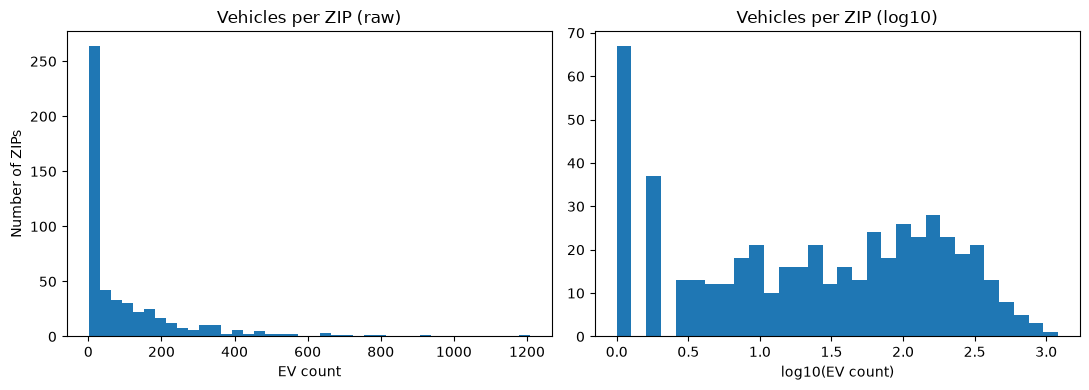

In [15]:
for n in [5, 10, 30]:
    k = (zip_summary["EV_Count"] < n).sum()
    print(f"ZIPs with fewer than {n} vehicles: {k} ({k/len(zip_summary):.0%})")

big = zip_summary[zip_summary["EV_Count"] >= 30]
print("Vehicles covered by ZIPs with 30+ vehicles:",
      big["EV_Count"].sum(), f"({big['EV_Count'].sum()/zip_summary['EV_Count'].sum():.0%})")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(zip_summary["EV_Count"], bins=40)
ax[0].set_title("Vehicles per ZIP (raw)")
ax[0].set_xlabel("EV count"); ax[0].set_ylabel("Number of ZIPs")
ax[1].hist(np.log10(zip_summary["EV_Count"]), bins=30)
ax[1].set_title("Vehicles per ZIP (log10)")
ax[1].set_xlabel("log10(EV count)")
plt.tight_layout()
plt.show()

## Vehicle type, model year, and manufacturer

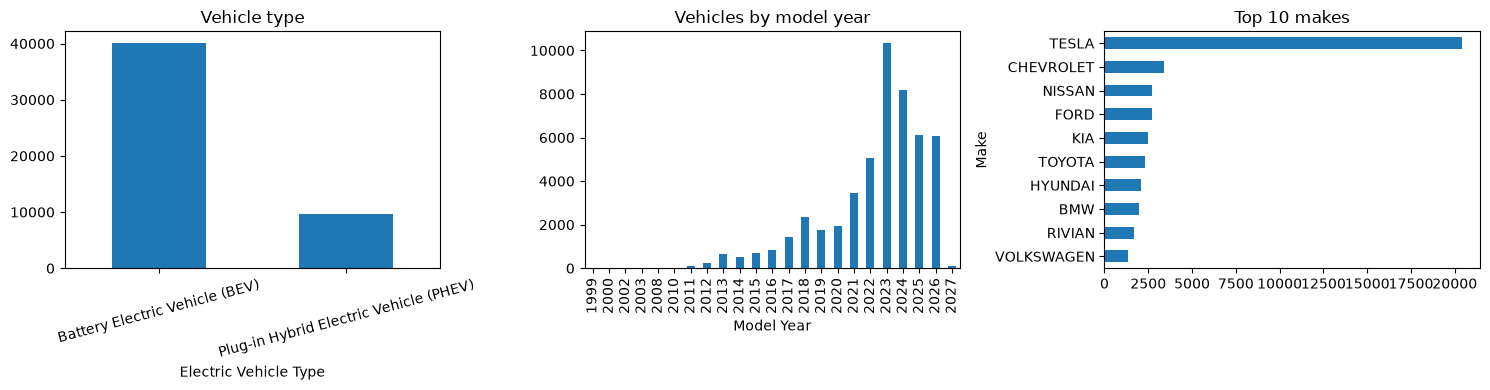

Share with zero or missing electric range: 66%


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

df_wa["Electric Vehicle Type"].value_counts().plot(kind="bar", ax=ax[0])
ax[0].set_title("Vehicle type")
ax[0].tick_params(axis="x", rotation=15)

df_wa["Model Year"].value_counts().sort_index().plot(kind="bar", ax=ax[1])
ax[1].set_title("Vehicles by model year")

df_wa["Make"].value_counts().head(10).plot(kind="barh", ax=ax[2])
ax[2].set_title("Top 10 makes")
ax[2].invert_yaxis()

plt.tight_layout()
plt.show()

print("Share with zero or missing electric range:",
      f"{df_wa['Electric Range Usable'].isna().mean():.0%}")

## Missing Range Information

In [17]:
tab = df_wa.groupby("Model Year").agg(
    Vehicles=("DOL Vehicle ID", "count"),
    Unavailable_Range_Share=("Electric Range Usable", lambda s: s.isna().mean())
)
print(tab[tab["Vehicles"] >= 50].round(4))

print()
print(df_wa.groupby("Electric Vehicle Type")["Electric Range Usable"]
      .apply(lambda s: s.isna().mean()).round(4))

            Vehicles  Unavailable_Range_Share
Model Year                                   
2011              99                   0.0000
2012             230                   0.0000
2013             660                   0.0000
2014             496                   0.0000
2015             709                   0.0000
2016             853                   0.0000
2017            1428                   0.0000
2018            2364                   0.0000
2019            1768                   0.0011
2020            1945                   0.0062
2021            3443                   0.7546
2022            5071                   0.8320
2023           10361                   0.8799
2024            8192                   0.7828
2025            6102                   0.7965
2026            6055                   0.8869
2027              83                   0.9639

Electric Vehicle Type
Battery Electric Vehicle (BEV)            0.8132
Plug-in Hybrid Electric Vehicle (PHEV)    0.0007
Name:

## ZIP-level relationships

ZIPs with 30+ vehicles: 249
                    EV_Count  BEV_Percentage  Avg_Model_Year  \
EV_Count                1.00            0.31            0.25   
BEV_Percentage          0.31            1.00            0.32   
Avg_Model_Year          0.25            0.32            1.00   
Avg_Electric_Range      0.13            0.66           -0.00   

                    Avg_Electric_Range  
EV_Count                          0.13  
BEV_Percentage                    0.66  
Avg_Model_Year                   -0.00  
Avg_Electric_Range                1.00  


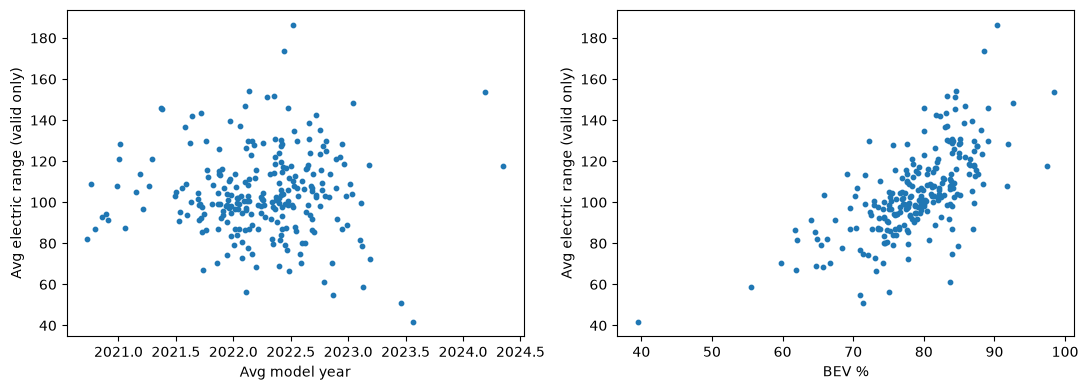

In [18]:
cols = ["EV_Count", "BEV_Percentage", "Avg_Model_Year", "Avg_Electric_Range"]
big = zip_summary[zip_summary["EV_Count"] >= 30]
print("ZIPs with 30+ vehicles:", len(big))
print(big[cols].corr().round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(big["Avg_Model_Year"], big["Avg_Electric_Range"], s=10)
ax[0].set_xlabel("Avg model year"); ax[0].set_ylabel("Avg electric range (valid only)")
ax[1].scatter(big["BEV_Percentage"], big["Avg_Electric_Range"], s=10)
ax[1].set_xlabel("BEV %"); ax[1].set_ylabel("Avg electric range (valid only)")
plt.tight_layout()
plt.show()

## ZIP and County Comparisons

In [19]:
top_zip = zip_summary.sort_values("EV_Count", ascending=False).head(5)
print(top_zip[["Postal Code", "EV_Count", "BEV_Percentage", "Avg_Model_Year"]])

df_wa["Is Tesla"] = df_wa["Make"] == "TESLA"
county = df_wa.groupby("County").agg(
    Vehicles=("DOL Vehicle ID", "count"),
    BEV_Share=("Is BEV", "mean"),
    Tesla_Share=("Is Tesla", "mean")
)
print(county[county["Vehicles"] >= 500].round(2).sort_values("Tesla_Share"))

   Postal Code  EV_Count  BEV_Percentage  Avg_Model_Year
39       98052      1208           88.25     2022.759106
10       98012       926           88.44     2023.011879
5        98006       791           86.35     2022.962073
25       98033       767           85.01     2022.671447
66       98115       697           78.77     2021.977044
           Vehicles  BEV_Share  Tesla_Share
County                                     
Island          520       0.76         0.28
Whatcom        1244       0.76         0.28
Kitsap         1662       0.77         0.30
Thurston       1800       0.76         0.31
Skagit          578       0.78         0.32
Spokane        1464       0.74         0.35
Pierce         4251       0.79         0.39
Clark          3084       0.77         0.39
Benton          742       0.75         0.44
King          24097       0.83         0.44
Snohomish      6402       0.83         0.47


## Vehicle-level descriptive statistics

We calculated vehicle-level descriptive statistics for model year and electric range. We also compared BEVs and PHEVs separately because their ranges differ considerably.

In [11]:

print("Model year and positive electric range:")
display(
    df_wa[["Model Year", "Electric Range Usable"]]
    .describe()
    .round(2)
)


type_summary = df_wa.groupby("Electric Vehicle Type").agg(
    Vehicle_Count=("DOL Vehicle ID", "count"),
    Positive_Range_Count=("Electric Range Usable", "count")
)

type_summary["Vehicle_Share_Percent"] = (
    type_summary["Vehicle_Count"] / len(df_wa) * 100
)

type_summary["Positive_Range_Available_Percent"] = (
    type_summary["Positive_Range_Count"]
    / type_summary["Vehicle_Count"] * 100
)

print("\nVehicle types and range availability:")
display(type_summary.round(2))


print("\nPositive electric range statistics by vehicle type (miles):")
range_by_type = (
    df_wa.groupby("Electric Vehicle Type")["Electric Range Usable"]
    .describe()
)

display(range_by_type.round(2))

Model year and positive electric range:


,Model Year,Electric Range Usable
count,49873.00,17202.00
mean,2022.34,105.02
std,3.11,96.16
min,1999.00,1.00
25%,2021.00,30.00
50%,2023.00,44.00
75%,2024.00,215.00
max,2027.00,337.00



Vehicle types and range availability:


,Vehicle_Count,Positive_Range_Count,Vehicle_Share_Percent,Positive_Range_Available_Percent
Electric Vehicle Type,,,,
Battery Electric Vehicle (BEV),40168,7504,80.54,18.68
Plug-in Hybrid Electric Vehicle (PHEV),9705,9698,19.46,99.93



Positive electric range statistics by vehicle type (miles):


,count,mean,std,min,25%,50%,75%,max
Electric Vehicle Type,,,,,,,,
Battery Electric Vehicle (BEV),7504.0,199.37,71.94,57.0,150.0,215.0,238.0,337.0
Plug-in Hybrid Electric Vehicle (PHEV),9698.0,32.01,13.43,1.0,22.0,32.0,38.0,153.0


## Positive electric range distributions

We compared positive recorded electric ranges separately for BEVs and PHEVs. Zero and missing ranges were excluded.

Range information is available for 18.68% of BEVs and 99.93% of
PHEVs, so these distributions may not represent the full fleet.

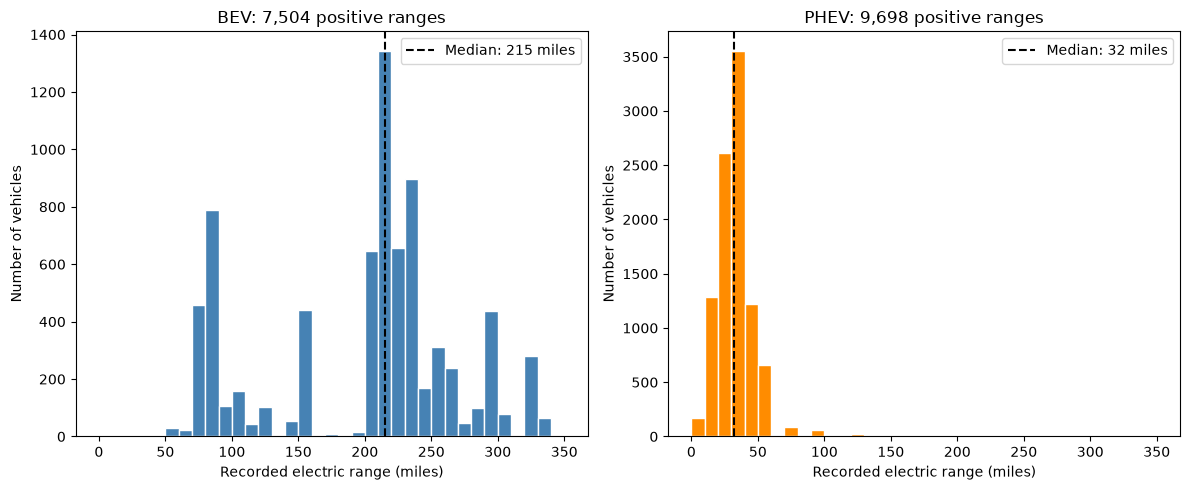

Positive electric range statistics (miles):


,count,mean,std,min,25%,50%,75%,max
Electric Vehicle Type,,,,,,,,
Battery Electric Vehicle (BEV),7504.0,199.37,71.94,57.0,150.0,215.0,238.0,337.0
Plug-in Hybrid Electric Vehicle (PHEV),9698.0,32.01,13.43,1.0,22.0,32.0,38.0,153.0


In [8]:
ev_types = {
    "BEV": "Battery Electric Vehicle (BEV)",
    "PHEV": "Plug-in Hybrid Electric Vehicle (PHEV)"
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

for ax, (label, full_name), color in zip(
    axes,
    ev_types.items(),
    ["steelblue", "darkorange"]
):
    ranges = df_wa.loc[
        df_wa["Electric Vehicle Type"] == full_name,
        "Electric Range Usable"
    ].dropna()

    ax.hist(
        ranges,
        bins=range(0, 351, 10),
        color=color,
        edgecolor="white"
    )

    ax.axvline(
        ranges.median(),
        color="black",
        linestyle="--",
        label=f"Median: {ranges.median():.0f} miles"
    )

    ax.set_title(f"{label}: {len(ranges):,} positive ranges")
    ax.set_xlabel("Recorded electric range (miles)")
    ax.set_ylabel("Number of vehicles")
    ax.legend()

plt.tight_layout()
plt.show()

print("Positive electric range statistics (miles):")
display(range_by_type.round(2))

## Model year, range, and availability

We explored how positive recorded electric range varies with model year, separately for BEVs and PHEVs. We also checked range availability by model year to identify gaps that could affect the comparisons.

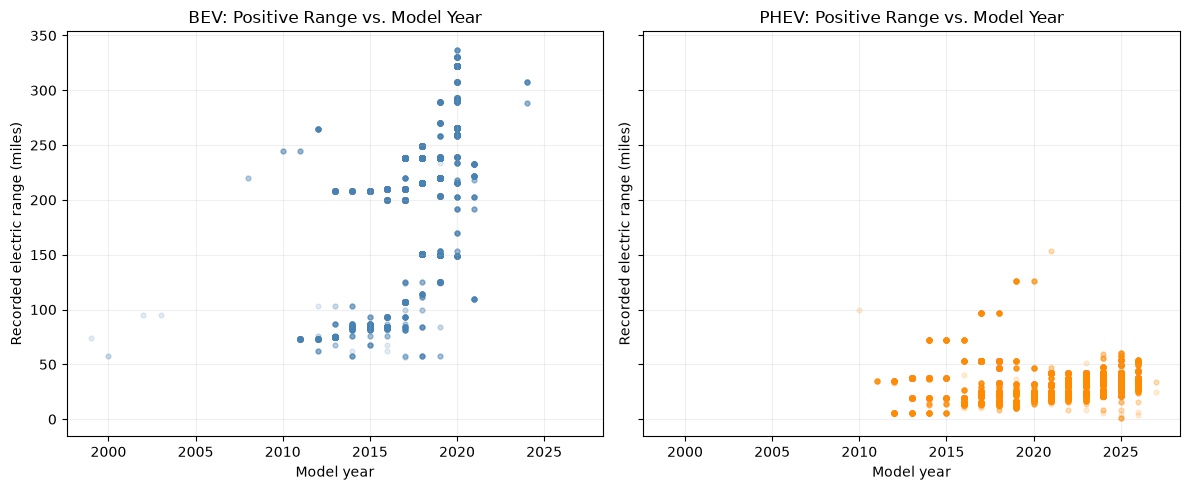

Range availability for model years 2020 onward:


Vehicle_Count  \
Electric Vehicle Type                  Model Year                  
Battery Electric Vehicle (BEV)         2020                 1628   
                                       2021                 2705   
                                       2022                 4219   
                                       2023                 9114   
                                       2024                 6429   
                                       2025                 4860   
                                       2026                 5368   
                                       2027                   78   
Plug-in Hybrid Electric Vehicle (PHEV) 2020                  317   
                                       2021                  738   
                                       2022                  852   
                                       2023                 1247   
                                       2024                 1763   
                                       2025                 1242   
                                       2026                  687   
                                       2027                    5   

                                                   Positive_Range_Count  \
Electric Vehicle Type                  Model Year                         
Battery Electric Vehicle (BEV)         2020                        1616   
                                       2021                         107   
                                       2022                           0   
                                       2023                           0   
                                       2024                          16   
                                       2025                           0   
                                       2026                           0   
                                       2027                           0   
Plug-in Hybrid Electric Vehicle (PHEV) 2020                         317   
                                       2021                         738   
                                       2022                         852   
                                       2023                        1244   
                                       2024                        1763   
                                       2025                        1242   
                                       2026                         685   
                                       2027                           3   

                                                   Median_Positive_Range  \
Electric Vehicle Type                  Model Year                          
Battery Electric Vehicle (BEV)         2020                        291.0   
                                       2021                        222.0   
                                       2022                          NaN   
                                       2023                          NaN   
                                       2024                        308.0   
                                       2025                          NaN   
                                       2026                          NaN   
                                       2027                          NaN   
Plug-in Hybrid Electric Vehicle (PHEV) 2020                         22.0   
                                       2021                         25.0   
                                       2022                         30.0   
                                       2023                         32.0   
                                       2024                         32.0   
                                       2025                         37.0   
                                       2026                         38.0   
                                       2027                         34.0   

                                                   Range_Available_Percent  
Electric Vehicle Type        

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for ax, (label, full_name), color in zip(
    axes,
    ev_types.items(),
    ["steelblue", "darkorange"]
):
    group = df_wa.loc[
        (df_wa["Electric Vehicle Type"] == full_name)
        & df_wa["Electric Range Usable"].notna()
    ]

    ax.scatter(
        group["Model Year"],
        group["Electric Range Usable"],
        alpha=0.15,
        s=12,
        color=color
    )

    ax.set_title(f"{label}: Positive Range vs. Model Year")
    ax.set_xlabel("Model year")
    ax.set_ylabel("Recorded electric range (miles)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


year_range_summary = df_wa.groupby(
    ["Electric Vehicle Type", "Model Year"]
).agg(
    Vehicle_Count=("DOL Vehicle ID", "count"),
    Positive_Range_Count=("Electric Range Usable", "count"),
    Median_Positive_Range=("Electric Range Usable", "median")
)

year_range_summary["Range_Available_Percent"] = (
    year_range_summary["Positive_Range_Count"]
    / year_range_summary["Vehicle_Count"] * 100
)

print("Range availability for model years 2020 onward:")
display(
    year_range_summary.loc[
        year_range_summary.index.get_level_values("Model Year") >= 2020
    ].round(2)
)

## Potential Range Outliers
We assessed unusual positive ranges separately for each vehicle type. IQR flags identify candidates for investigation, not confirmed errors. The earlier quality report used all 50,000 records; this calculation uses only the Washington subset, so counts can differ. Model-year screening also does not establish that an unusual year is invalid.


In [10]:
outlier_rows = []
for ev_type, group in df_wa.groupby("Electric Vehicle Type"):
    ranges = group["Electric Range Usable"].dropna()
    q1, q3 = ranges.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({"EV_Type": ev_type, "Positive_Ranges": len(ranges),
                         "Lower_Fence": low, "Upper_Fence": high,
                         "Potential_Outliers": ((ranges < low) | (ranges > high)).sum()})
display(pd.DataFrame(outlier_rows))
print("Range observations per retained ZIP (30+ sampled vehicles):")
display(big["Valid_Range_Count"].describe())


,EV_Type,Positive_Ranges,Lower_Fence,Upper_Fence,Potential_Outliers
0,Battery Electric Vehicle (BEV),7504,18.0,370.0,0
1,Plug-in Hybrid Electric Vehicle (PHEV),9698,-2.0,62.0,174


Range observations per retained ZIP (30+ sampled vehicles):


count    249.000000
mean      65.775100
std       51.038466
min        2.000000
25%       29.000000
50%       54.000000
75%       88.000000
max      305.000000
Name: Valid_Range_Count, dtype: float64

## Observations

1. The analysis includes 49,873 Washington vehicles across 509 ZIP codes from the fixed 50,000-row sample.
2. Sampled EV counts per ZIP are strongly right-skewed: the median is 27, the mean is 97.98, and the maximum is 1,208. Of the ZIP groups, 260 (51%) contain fewer than 30 vehicles; groups with at least 30 contain approximately 96% of sampled Washington vehicles.
3. BEVs account for 80.54% of the Washington sample and PHEVs for 19.46%. Tesla accounts for 40.94%.
4. Model year 2023 is most common, with 10,361 vehicles (20.77%). Vehicles with model years 2021 or later represent 78.81%. These figures describe fleet composition, rather than annual registrations or sales.
5. Positive recorded ranges are available for 18.68% of BEVs and 99.93% of PHEVs. Among available records, BEVs have a mean range of 199.37 miles and median of 215 miles; PHEVs have a mean of 32.01 miles and median of 32 miles.
6. Zero ranges occur before 2021 but increase sharply beginning in 2021. BEV positive-range availability falls from 99.26% in 2020 to 3.96% in 2021, with no positive ranges for 2022 or 2023. Year–range comparisons therefore need to account for which records have range information.
7. Among ZIP groups with at least 30 sampled vehicles, average positive range correlates with BEV percentage (r ≈ 0.66) and has approximately zero linear correlation with average model year. These are ZIP-level relationships among available ranges.
8. The five largest sampled ZIP groups are 98052, 98012, 98006, 98033, and 98115, containing 697–1,208 vehicles each. King County contains about 48% of sampled Washington vehicles. Among counties with at least 500 sampled vehicles, BEV shares are approximately 74%–83%, and Tesla shares are approximately 28%–47%.
9. 51 ZIP groups have no positive-range observations, and 184 contain fewer than 10 sampled vehicles. These ZIP codes have little data, so their averages may be less reliable.
10. Positive-range distributions differ between BEVs and PHEVs. The IQR rule flagged 174 PHEVs and no BEVs. These are potential outliers, not confirmed errors.

## Revised Mining Questions

1. **Clustering:** What distinct ZIP-level fleet profiles emerge from sampled EV counts, vehicle composition, model years, and available range information?
2. **Association-rule mining:** Which combinations of manufacturer, vehicle type, and model-year group occur more frequently than expected from their individual frequencies?
3. **Anomaly detection:** Which vehicle records have unusual positive ranges or model-year values, considering vehicle type and range availability, and do they reflect genuine outliers or possible data errors?
4. **Model year and range:** How does positive recorded range vary with model year for BEVs and PHEVs, and which comparisons are supported by the available records?
